# Baseline Moving Averages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

## Import Data

In [2]:
df = pd.read_parquet(r"../Data/cleaned_data/all.parquet")
df.head()

,interval_start_utc,interval_end_utc,publish_time_utc_rtm,load_forecast,lmp_rtm,energy_rtm,congestion_rtm,loss_rtm,publish_time_utc_dam,north_wind,...,south_wind,miso_wind,north_solar,central_solar,south_solar,miso_solar,lmp_dam,energy_dam,congestion_dam,loss_dam
0,2023-03-25 01:55:00+00:00,2023-03-25 02:00:00+00:00,2023-03-24 05:00:00+00:00,71099,28.03,22.55,5.17,0.31,2023-03-23 20:15:12+00:00,5416.1,...,0.0,9920.8,3.9,1.0,1.2,6.1,26.92,26.09,1.66,-0.83
1,2023-03-25 02:00:00+00:00,2023-03-25 02:05:00+00:00,2023-03-24 05:00:00+00:00,70934,25.08,21.13,3.70,0.25,2023-03-23 20:15:12+00:00,6123.7,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
2,2023-03-25 02:05:00+00:00,2023-03-25 02:10:00+00:00,2023-03-24 05:00:00+00:00,70768,27.07,23.40,3.46,0.21,2023-03-23 20:15:12+00:00,6123.7,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
3,2023-03-25 02:10:00+00:00,2023-03-25 02:15:00+00:00,2023-03-24 05:00:00+00:00,70602,26.10,22.67,3.21,0.22,2023-03-23 20:15:12+00:00,6123.7,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
4,2023-03-25 02:15:00+00:00,2023-03-25 02:20:00+00:00,2023-03-24 05:00:00+00:00,70436,24.82,23.07,1.57,0.18,2023-03-23 20:15:12+00:00,6123.7,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85


## Configuration and Hyper Parameters

In [ ]:
DATE_COL = "interval_start_utc"
TARGET_COL = "lmp_rtm"

# Train / Validation / Test Cutoffs (Matching SARIMAX Setup)
TRAIN_END_DATE = "2025-07-01 00:00:00+00:00"
VAL_END_DATE   = "2026-07-01 00:00:00+00:00"

# Horizon and Validation Windowing
FORECAST_HORIZON = 288       # 288 steps = 24 hours (at 5-min resolution)
STRIDE_STEPS     = 300        # Step size for rolling validation (48 steps = 6 hours), 300 for now for consistency

# Moving Average Lookback Window Options (in Steps)
# 288 steps  = 1 Day
# 864 steps  = 3 Days
# 2016 steps = 7 Days
# 4032 steps = 14 Days
LOOKBACK_WINDOWS = {
    "Persistence (1-Day Prior Profile)": 288,
    "3-Day Rolling Average": 864,
    "7-Day Rolling Average": 2016,
    "14-Day Rolling Average": 4032
}

## Data Cleaning and Pre-processing

In [4]:
def preprocess_baseline_data(df: pd.DataFrame) -> pd.DataFrame:
    """
    Ensures datetime formatting, sorts chronologically, and handles missing 
    values using time-based interpolation to mirror the main pipeline.
    """
    data = df.copy()
    data[DATE_COL] = pd.to_datetime(data[DATE_COL])
    data = data.sort_values(DATE_COL).reset_index(drop=True)
    data = data.set_index(DATE_COL)
    
    if data[TARGET_COL].isnull().sum() > 0:
        data[TARGET_COL] = data[TARGET_COL].interpolate(method='time').bfill().ffill()

    # Set all values over 1000 to 1000 to match the main pipeline's preprocessing
    data[TARGET_COL] = data[TARGET_COL].clip(upper=1000)
    return data

In [5]:
df_clean = preprocess_baseline_data(df)

## Model

In [6]:
def generate_persistence_forecast(y_history: pd.Series, horizon: int = 288) -> np.ndarray:
    """
    Persistence Baseline: Uses the exact same 288-step (24-hour) profile 
    from yesterday as the forecast for tomorrow.
    """
    return y_history.iloc[-horizon:].values

def generate_moving_average_forecast(y_history: pd.Series, lookback_steps: int, horizon: int = 288) -> np.ndarray:
    """
    Moving Average Baseline: Calculates the intraday 5-minute profile averaged 
    across 'N' prior days in the lookback window.
    """
    recent_history = y_history.iloc[-lookback_steps:].values
    # Reshape history into days (Num_Days, 288)
    num_days = len(recent_history) // horizon
    if num_days < 1:
        # Fallback to simple mean if history is shorter than lookback
        return np.full(horizon, recent_history.mean())
    
    # Trim to exact multiples of horizon
    trimmed_history = recent_history[-num_days * horizon :]
    daily_matrix = trimmed_history.reshape(num_days, horizon)
    
    # Mean profile across the historical days for each 5-minute interval
    avg_profile = daily_matrix.mean(axis=0)
    return avg_profile

## Validation Loop

In [7]:
def run_rolling_baseline_validation(
    df: pd.DataFrame,
    target_col: str,
    train_end: str,
    val_end: str,
    lookback_dict: dict,
    horizon: int = 288,
    stride: int = 48
):
    """
    Runs rolling validation for all moving average baseline variants over 
    the exact same validation origins as the SARIMAX model.
    """
    val_mask = (df.index >= train_end) & (df.index < val_end)
    val_indices = np.where(val_mask)[0]
    
    # Valid start indices given stride and horizon
    valid_start_indices = [idx for idx in val_indices[::stride] if idx + horizon <= len(df)]
    
    results = {name: [] for name in lookback_dict.keys()}
    actuals = []
    timestamps = []
    
    max_lookback = max(lookback_dict.values())
    
    print(f"Running Baseline Validation across {len(valid_start_indices)} rolling origins...")
    
    for t_origin in valid_start_indices:
        # Ground truth 288-step horizon
        real_actual = df[target_col].iloc[t_origin : t_origin + horizon].values
        actuals.append(real_actual)
        timestamps.append(df.index[t_origin : t_origin + horizon])
        
        # Historical slice up to t_origin
        t_start = max(0, t_origin - max_lookback)
        y_history = df[target_col].iloc[t_start:t_origin]
        
        # Generate predictions for each baseline model
        for name, lookback in lookback_dict.items():
            if "Persistence" in name:
                pred = generate_persistence_forecast(y_history, horizon=horizon)
            else:
                pred = generate_moving_average_forecast(y_history, lookback_steps=lookback, horizon=horizon)
            
            results[name].append(pred)
            
    # Convert lists to arrays
    actuals = np.array(actuals)
    for name in results:
        results[name] = np.array(results[name])
        
    return results, actuals, timestamps

In [8]:
baseline_preds, actuals, timestamps = run_rolling_baseline_validation(
    df=df_clean,
    target_col=TARGET_COL,
    train_end=TRAIN_END_DATE,
    val_end=VAL_END_DATE,
    lookback_dict=LOOKBACK_WINDOWS,
    horizon=FORECAST_HORIZON,
    stride=STRIDE_STEPS
)

Running Baseline Validation across 2190 rolling origins...


## Compare and Visualize

In [9]:
def evaluate_all_baselines(baseline_results: dict, actuals: np.ndarray):
    """
    Prints a comparative metric summary table (MAE & RMSE) across all 
    tested lookback windows and baselines.
    """
    print("\n" + "=" * 65)
    print(f"{'BASELINE MODEL VARIANT':<35} | {'MAE ($/MWh)':<12} | {'RMSE ($/MWh)':<12}")
    print("=" * 65)
    
    summary_metrics = {}
    
    for name, forecasts in baseline_results.items():
        mae = mean_absolute_error(actuals.flatten(), forecasts.flatten())
        rmse = np.sqrt(mean_squared_error(actuals.flatten(), forecasts.flatten()))
        summary_metrics[name] = {"MAE": mae, "RMSE": rmse}
        
        print(f"{name:<35} | ${mae:<11.2f} | ${rmse:<11.2f}")
        
    print("=" * 65)
    return summary_metrics

def plot_baseline_vs_actual_sample(
    baseline_results: dict,
    actuals: np.ndarray,
    timestamps: list,
    sample_idx: int = 0
):
    """
    Plots a sample 24-hour horizon comparing all baseline lookback predictions 
    against actual LMP values for a selected rolling window origin.
    """
    plt.figure(figsize=(14, 6))
    time_axis = timestamps[sample_idx]
    
    # Plot Actual LMP
    plt.plot(time_axis, actuals[sample_idx], label='Actual LMP', color='black', linewidth=2, alpha=0.8)
    
    # Plot Each Baseline Variant
    colors = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3']
    for (name, forecasts), color in zip(baseline_results.items(), colors):
        plt.plot(time_axis, forecasts[sample_idx], label=name, linestyle='--', linewidth=1.5, color=color)
        
    start_time_str = time_axis[0].strftime('%Y-%m-%d %H:%M UTC')
    plt.title(f"Baseline Comparison Horizon (Origin $t=0$: {start_time_str})", fontsize=13, fontweight='bold')
    plt.ylabel("LMP ($/MWh)")
    plt.xlabel("Time (UTC)")
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='upper left', frameon=True)
    plt.tick_params(axis='x', rotation=30)
    plt.tight_layout()
    plt.show()


BASELINE MODEL VARIANT              | MAE ($/MWh)  | RMSE ($/MWh)
Persistence (1-Day Prior Profile)   | $25.37       | $74.28      
3-Day Rolling Average               | $24.31       | $66.12      
7-Day Rolling Average               | $22.88       | $61.73      
14-Day Rolling Average              | $23.22       | $61.37      


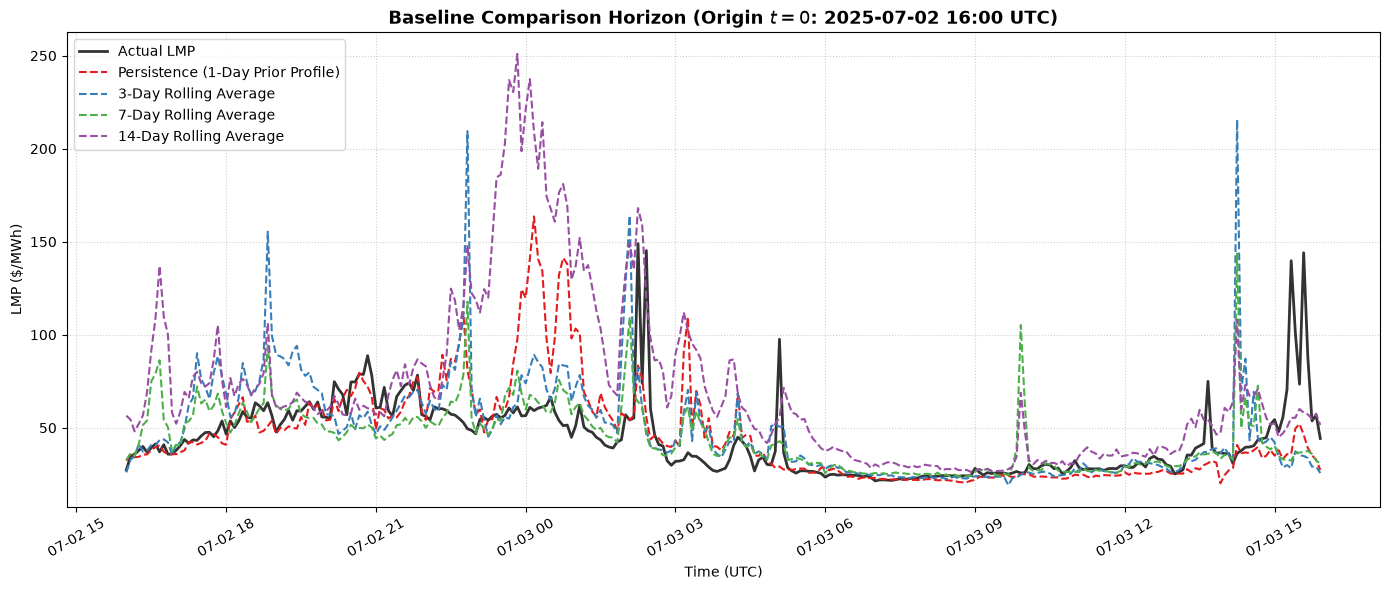

In [10]:
# Comparison Table
metrics_summary = evaluate_all_baselines(baseline_preds, actuals)

# Plot Sample Horizon Comparison
plot_baseline_vs_actual_sample(baseline_preds, actuals, timestamps, sample_idx=10)